En este Análisis exploratorio tendre la siguiente estructura 
## 1. Carga de datos
## 2. Revisión inicial y calidad de datos
## 3. Analisis exploratorio
## 4. Variables
## 5. Modelado financiero
## 6. Evaluación 
## 7. Conclusiones

In [1]:
#Carga de datos 
import pandas as pd

df = pd.read_csv(r"C:\Users\Carlo\OneDrive\Documentos\Github\credit-risk-analytics\default_of_credit_card_clients.csv")
list(df.columns)

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default payment next month']

In [2]:
#Revisión inicial y calidad de datos

In [3]:
print(df.shape)
df.info()

(30000, 25)
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_

In [4]:
#datos sucios
df.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [7]:
df["EDUCATION"].value_counts().sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [8]:
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

In [9]:
#Hallazgos del resumen estadístico:
#- `EDUCATION` trae valores 0, 5 y 6, y `MARRIAGE` trae 0. El diccionario no define el 0 en ninguna de las dos, y el 5 y 6 aparecen como "unknown".
#- Los `BILL_AMT` tienen valores negativos. Son saldos a favor (el cliente pagó de más), no errores, así que los conservo.
#- El 22.1% de los clientes cayó en default, por lo que la clase está desbalanceada. Más adelante no voy a evaluar el modelo solo con accuracy.

df["EDUCATION"].value_counts().sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [10]:
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

In [11]:
#Los valores sin definición suman 345 registros en `EDUCATION` (0, 5 y 6) y 54 en `MARRIAGE` (0), aproximadamente 1.3% de la base.

#**Decisión:** los agrupo en la categoría "others" (4 y 3 respectivamente) en lugar de eliminarlos, para conservar el historial de pagos de esos clientes.

In [12]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
print(df["EDUCATION"].value_counts().sort_index())
print(df["MARRIAGE"].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


### 3. Análisis exploratorio (EDA)
Objetivo: identificar qué variables se relacionan más con el default.
    

In [13]:
df = df.rename(columns={"PAY_0": "PAY_1", "default payment next month": "default"})

In [14]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(df.groupby(col)["default"].mean().round(3), "\n")

SEX
1    0.242
2    0.208
Name: default, dtype: float64 

EDUCATION
1    0.192
2    0.237
3    0.252
4    0.071
Name: default, dtype: float64 

MARRIAGE
1    0.235
2    0.209
3    0.236
Name: default, dtype: float64 



In [15]:
df.groupby("PAY_1")["default"].agg(["count", "mean"]).round(3)

,count,mean
PAY_1,,
-2,2759,0.132
-1,5686,0.168
0,14737,0.128
1,3688,0.339
2,2667,0.691
3,322,0.758
4,76,0.684
5,26,0.500
6,11,0.545


**Hallazgos:**
- Las variables demográficas (SEX, EDUCATION, MARRIAGE) muestran tasas de default entre 19% y 25%, cercanas al promedio de 22.1%, así que separan poco el riesgo.
- PAY_1 es la variable más discriminante: sin atraso la tasa es de 13%-17%, con 1 mes de atraso sube a 34% y con 2 meses o más ronda el 70%.
- La morosidad reciente pesa mucho más que el perfil demográfico del cliente.

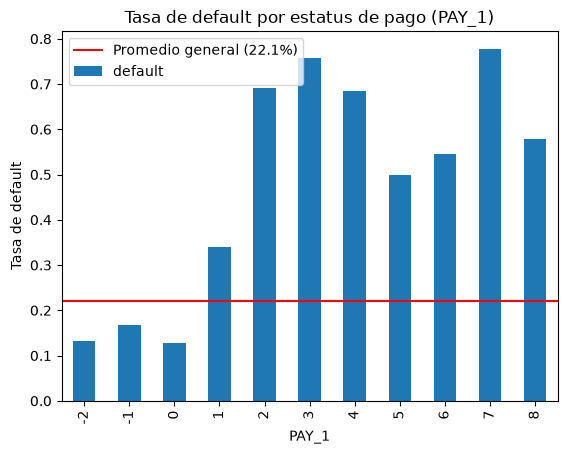

In [16]:
import matplotlib.pyplot as plt

tasa = df.groupby("PAY_1")["default"].mean()
tasa.plot(kind="bar")
tasa.plot(kind="bar", label="_nolegend_")
plt.legend(loc="upper right")
plt.axhline(df["default"].mean(), color="red", linestyle="-", label="Promedio general (22.1%)")
plt.title("Tasa de default por estatus de pago (PAY_1)")
plt.ylabel("Tasa de default")
plt.legend()
plt.show()

In [17]:
#variables
df["LIMIT_BIN"] = pd.qcut(df["LIMIT_BAL"], 5)
df.groupby("LIMIT_BIN", observed=True)["default"].agg(["count", "mean"]).round(3)

,count,mean
LIMIT_BIN,,
"(9999.999, 50000.0]",7676,0.318
"(50000.0, 100000.0]",4822,0.258
"(100000.0, 180000.0]",6123,0.199
"(180000.0, 270000.0]",5421,0.169
"(270000.0, 1000000.0]",5958,0.138


In [18]:
df["AGE_BIN"] = pd.cut(df["AGE"], [20, 30, 40, 50, 60, 80])
df.groupby("AGE_BIN", observed=True)["default"].agg(["count", "mean"]).round(3)

,count,mean
AGE_BIN,,
"(20, 30]",11013,0.224
"(30, 40]",10713,0.204
"(40, 50]",6005,0.233
"(50, 60]",1997,0.252
"(60, 80]",272,0.268


- LIMIT_BAL separa bien el riesgo: la tasa de default baja de 31.8% (límite hasta 50,000) a 13.8% (límite mayor a 270,000). Probablemente refleja la evaluación de riesgo que el banco hizo al asignar el límite.
- AGE muestra una relación débil (20.4% a 26.8%), y el grupo de 60 a 80 años tiene solo 272 clientes.

## 4. Variables
Construyo variables que reflejan el comportamiento de pago, como lo haría en un análisis de riesgo de crédito.

In [19]:
# Utilización de la línea: qué proporción del límite está usando
df["UTIL_1"] = df["BILL_AMT1"] / df["LIMIT_BAL"]

# Cuántos de los últimos 6 meses tuvo atraso
pay_cols = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
df["MESES_ATRASO"] = (df[pay_cols] >= 1).sum(axis=1)

In [20]:
df.groupby("MESES_ATRASO")["default"].agg(["count", "mean"]).round(3)

,count,mean
MESES_ATRASO,,
0,19931,0.117
1,4426,0.298
2,1899,0.388
3,1154,0.509
4,951,0.573
5,298,0.574
6,1341,0.703


- MESES_ATRASO (cantidad de meses con atraso en el semestre) discrimina muy bien el riesgo: la tasa de default sube de 11.7% (sin atrasos) a 70.3% (atraso en los 6 meses).
- A diferencia de PAY_1, todos sus grupos tienen cientos de clientes, por lo que la tendencia es más estable.

In [21]:
df["UTIL_BIN"] = pd.cut(df["UTIL_1"], [-10, 0, 0.25, 0.5, 0.75, 1, 100])
df.groupby("UTIL_BIN", observed=True)["default"].agg(["count", "mean"]).round(3)

,count,mean
UTIL_BIN,,
"(-10.0, 0.0]",2598,0.247
"(0.0, 0.25]",11440,0.168
"(0.25, 0.5]",3588,0.217
"(0.5, 0.75]",3579,0.260
"(0.75, 1.0]",6680,0.258
"(1.0, 100.0]",2115,0.301


- La utilización de la línea (saldo / límite) muestra una relación moderada con el default: 16.8% con uso de hasta 25% del límite y 30.1% en clientes que rebasan el límite.
- La relación no es completamente monótona; el grupo con saldo cero o a favor (24.7%) mezcla situaciones distintas y requiere análisis aparte.

In [22]:
df["PAGO_RATIO"] = (df["PAY_AMT1"] / df["BILL_AMT2"]).where(df["BILL_AMT2"] > 0)
df["PAGO_BIN"] = pd.cut(df["PAGO_RATIO"], [-0.01, 0, 0.1, 0.5, 1, float("inf")])
df.groupby("PAGO_BIN", observed=True)["default"].agg(["count", "mean"]).round(3)

,count,mean
PAGO_BIN,,
"(-0.01, 0.0]",2220,0.525
"(0.0, 0.1]",12696,0.213
"(0.1, 0.5]",4344,0.221
"(0.5, 1.0]",4808,0.161
"(1.0, inf]",2757,0.104


- PAGO_RATIO (pago de septiembre / saldo de agosto) identifica bien los extremos: los clientes que no pagaron nada tienen 52.5% de default, mientras que quienes pagaron más del 100% del saldo tienen 10.4%.
- Entre 0% y 50% de pago la tasa se mantiene cerca del promedio (21%-22%), por lo que la señal está en los extremos.
- Alrededor del 10.6% de los clientes tiene saldo cero o a favor en agosto, por lo que el ratio no aplica y requiere un tratamiento especial en el modelo.

## 5. Modelado
Separo 80% de los clientes para entrenar y 20% para evaluar.

In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["ID", "default", "LIMIT_BIN", "AGE_BIN", "UTIL_BIN", "PAGO_BIN"])
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(y_train.mean(), y_test.mean())

0.22120833333333334 0.22116666666666668


### Modelo base: regresión logística

In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

modelo_lr = make_pipeline(
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)
modelo_lr.fit(X_train, y_train)

prob = modelo_lr.predict_proba(X_test)[:, 1]
print("AUC:", round(roc_auc_score(y_test, prob), 3))
print("KS:", round(ks_2samp(prob[y_test == 1], prob[y_test == 0]).statistic, 3))

AUC: 0.743
KS: 0.383


Resultados del modelo base (regresión logística, sobre el 20% de prueba): AUC = 0.743 y KS = 0.383. Este será el punto de comparación para modelos más complejos.

### Modelo 2: Gradient Boosting

In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier

modelo_gb = HistGradientBoostingClassifier(random_state=42)
modelo_gb.fit(X_train, y_train)

prob_gb = modelo_gb.predict_proba(X_test)[:, 1]
print("AUC:", round(roc_auc_score(y_test, prob_gb), 3))
print("KS:", round(ks_2samp(prob_gb[y_test == 1], prob_gb[y_test == 0]).statistic, 3))

AUC: 0.781
KS: 0.426


## 6. Evaluación

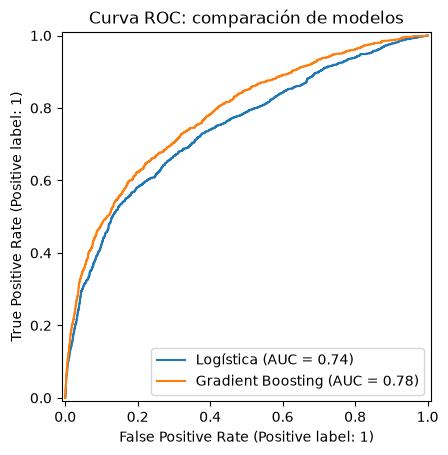

In [26]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots()
RocCurveDisplay.from_predictions(y_test, prob, name="Logística", ax=ax)
RocCurveDisplay.from_predictions(y_test, prob_gb, name="Gradient Boosting", ax=ax)
plt.title("Curva ROC: comparación de modelos")
plt.show()

## 7. Conclusiones

**Hallazgos del análisis**
- El 22.1% de los 30,000 clientes cayó en default, por lo que la clase está desbalanceada y evalué con AUC y KS en lugar de accuracy.
- La morosidad reciente es la señal más fuerte: la tasa de default pasa de 11.7% en clientes sin meses de atraso a 70.3% en quienes se atrasaron los 6 meses.
- El comportamiento de pago pesa más que el perfil demográfico: SEX, EDUCATION, MARRIAGE y AGE muestran tasas entre 19% y 27%, cercanas al promedio.
- Los clientes que no pagaron nada el último mes tienen 52.5% de default, mientras que quienes pagaron más del 100% de su saldo tienen 10.4%.
- Los límites de crédito bajos se asocian con más default (31.8% con límite hasta 50,000 vs. 13.8% con más de 270,000), probablemente porque el límite ya refleja la evaluación de riesgo del banco.

**Resultados de los modelos (20% de prueba)**

| Modelo | AUC | KS |
|---|---|---|
| Regresión logística | 0.743 | 0.383 |
| Gradient Boosting | 0.781 | 0.426 |

El Gradient Boosting supera al modelo base con parámetros por default, lo que sugiere relaciones no lineales entre las variables y el default.

**Implicaciones de negocio**
- Un sistema de alertas tempranas debería enfocarse en clientes con atrasos recurrentes y en quienes dejan de pagar por completo, pues concentran el mayor riesgo.
- Los modelos permiten ordenar a los clientes por probabilidad de default y priorizar la cobranza o la revisión de límites.

**Limitaciones y siguientes pasos**
- Los resultados provienen de un solo corte train/test; falta validar con validación cruzada.
- No se ajustaron hiperparámetros ni se definió un punto de corte según el costo de cada error.
- Los datos son de clientes de Taiwán en 2005, por lo que no se pueden trasladar directamente al mercado mexicano actual.
- Alrededor del 10.6% de los clientes no tenía saldo en agosto, por lo que PAGO_RATIO se imputó.